<a href="https://colab.research.google.com/github/Genie4pe/newcitrus/blob/main/CitrusDisease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, shutil, glob
from google.colab import files

print("📤 Please upload your kaggle.json now...")
uploaded = files.upload()

# Find the uploaded kaggle file no matter where Colab put it
kaggle_path = None
for fname in uploaded.keys():
    kaggle_path = fname
    break

if not kaggle_path:
    # Search common Colab dump locations
    for candidate in glob.glob("/content/*.json") + glob.glob("/root/*.json"):
        if "kaggle" in candidate.lower():
            kaggle_path = candidate
            break

if not kaggle_path:
    raise FileNotFoundError("❌ kaggle.json not found. Please upload it.")

dest = os.path.expanduser("~/.kaggle/kaggle.json")
os.makedirs(os.path.dirname(dest), exist_ok=True)
shutil.copy2(kaggle_path, dest)
os.chmod(dest, 0o600)
print(f"✅ Kaggle API configured")

import subprocess
r = subprocess.run(["kaggle", "datasets", "list", "--search", "orange"],
                   capture_output=True, text=True)
print("✅ Kaggle API working" if r.returncode == 0 else f"⚠️ {r.stderr[:100]}")

📤 Please upload your kaggle.json now...


Saving kaggle.json to kaggle (2).json
✅ Kaggle API configured
✅ Kaggle API working


In [ ]:
!pip install -q kaggle split-folders pillow scikit-learn matplotlib seaborn
print("All packages installed")

All packages installed


In [ ]:
import os, subprocess

DOWNLOAD_DIR = "/content/raw_downloads"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)

datasets = [
    # Dataset 1: Orange leaf disease - 41K images (Canker, Greening, Black Spot, Healthy + more)
    ("shuvokumarbasak4004/orange-leaf-disease-dataset", "orange_leaf_ds"),
    # Dataset 2: Jonathan Silva orange diseases (Canker, Greening, Black Spot)
    ("jonathansilva2020/orange-diseases-dataset", "jonathan_ds"),
    # Dataset 3: Citrus diseases from Jonathan Silva (has more classes)
    ("jonathansilva2020/dataset-for-classification-of-citrus-diseases", "citrus_ds"),
    # Dataset 4: Citrus leaves (nutrient deficiency + diseases)
    ("sourabh2001/citrus-leaves-dataset", "citrus_leaves"),
]

for slug, folder in datasets:
    dest = f"{DOWNLOAD_DIR}/{folder}"
    os.makedirs(dest, exist_ok=True)
    print(f"⬇️  Downloading {slug}...")
    result = subprocess.run(
        ["kaggle", "datasets", "download", "-d", slug, "-p", dest, "--unzip"],
        capture_output=True, text=True
    )
    if result.returncode == 0:
        print(f"   ✅ Done")
    else:
        print(f"   ⚠️  Warning: {result.stderr[:150]}")

print("\n✅ All downloads complete")

# Show what we got
for root, dirs, files in os.walk(DOWNLOAD_DIR):
    level = root.replace(DOWNLOAD_DIR, '').count(os.sep)
    if level <= 2:
        indent = '  ' * level
        print(f'{indent}{os.path.basename(root)}/ ({len(files)} files)')

⬇️  Downloading shuvokumarbasak4004/orange-leaf-disease-dataset...
   ✅ Done
⬇️  Downloading jonathansilva2020/orange-diseases-dataset...
   ✅ Done
⬇️  Downloading jonathansilva2020/dataset-for-classification-of-citrus-diseases...
   ✅ Done
⬇️  Downloading sourabh2001/citrus-leaves-dataset...
   ✅ Done

✅ All downloads complete
raw_downloads/ (0 files)
  citrus_leaves/ (0 files)
    Leaves/ (0 files)
  jonathan_ds/ (0 files)
    train/ (0 files)
    test/ (0 files)
  orange_leaf_ds/ (0 files)
    train/ (0 files)
  citrus_ds/ (0 files)
    dataset/ (0 files)


In [ ]:
import os

DOWNLOAD_DIR = "/content/raw_downloads"

# Walk all directories and show image counts
print("📂 Scanning all downloaded folders...\n")
all_dirs = {}
for root, dirs, files in os.walk(DOWNLOAD_DIR):
    imgs = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))]
    if imgs:
        rel = root.replace(DOWNLOAD_DIR + "/", "")
        all_dirs[root] = len(imgs)
        print(f"  [{len(imgs):5d} imgs]  {rel}")

print(f"\nTotal image-containing folders: {len(all_dirs)}")

📂 Scanning all downloaded folders...

  [  485 imgs]  citrus_leaves/Leaves/healthy
  [  163 imgs]  citrus_leaves/Leaves/canker
  [   13 imgs]  citrus_leaves/Leaves/Melanose
  [  204 imgs]  citrus_leaves/Leaves/greening
  [  171 imgs]  citrus_leaves/Leaves/Black spot
  [  179 imgs]  jonathan_ds/train/canker
  [  347 imgs]  jonathan_ds/train/grenning
  [  281 imgs]  jonathan_ds/train/fresh
  [  184 imgs]  jonathan_ds/train/blackspot
  [   22 imgs]  jonathan_ds/test/canker
  [   22 imgs]  jonathan_ds/test/grenning
  [   33 imgs]  jonathan_ds/test/fresh
  [   22 imgs]  jonathan_ds/test/blackspot
  [ 3200 imgs]  orange_leaf_ds/train/Young_Healthy_Leaf_Orange
  [ 6384 imgs]  orange_leaf_ds/train/Healthy_Leaf_Orange
  [ 4800 imgs]  orange_leaf_ds/train/Multiple_Diseases_Leaf_Orange
  [12800 imgs]  orange_leaf_ds/train/Citrus_Nutrient_Deficiency_Yellow_Leaf_Orange
  [11248 imgs]  orange_leaf_ds/train/Citrus_Canker_Diseases_Leaf_Orange
  [ 1002 imgs]  citrus_ds/dataset/dataset/train/citrus-cank

In [ ]:
import os, shutil
from pathlib import Path

DOWNLOAD_DIR = "/content/raw_downloads"
DATASET_DIR  = "/content/orange_dataset"

# Our 4 target classes
TARGET_CLASSES = ["Canker", "Greening", "Black_Spot", "Nutrient_Deficiency"]
for cls in TARGET_CLASSES:
    os.makedirs(f"{DATASET_DIR}/{cls}", exist_ok=True)

# Keyword maps — any folder whose name contains these keywords maps to the class
CLASS_KEYWORDS = {
    "Canker":              ["canker", "bacterial canker", "citrus canker"],
    "Greening":            ["greening", "huanglongbing", "hlb", "haunglongbing",
                            "citrus greening", "citrus_greening"],
    "Black_Spot":          ["black spot", "black_spot", "blackspot", "melanose",
                            "scab", "dark spot", "blight", "brown spot"],
    "Nutrient_Deficiency": ["nutrient", "deficien", "zinc", "nitrogen", "magnesium",
                            "iron", "chlorosis", "nutritional", "mineral",
                            "yellowing", "healthy"],  # healthy leaves also serve as base
}

def get_class_for_folder(folder_name: str):
    name_lower = folder_name.lower()
    for cls, keywords in CLASS_KEYWORDS.items():
        if any(kw in name_lower for kw in keywords):
            return cls
    return None

copied = {cls: 0 for cls in TARGET_CLASSES}
unmatched = []

for root, dirs, files in os.walk(DOWNLOAD_DIR):
    folder_name = os.path.basename(root)
    target_class = get_class_for_folder(folder_name)
    if target_class is None:
        continue
    imgs = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))]
    if not imgs:
        continue
    for i, img in enumerate(imgs):
        src = os.path.join(root, img)
        dst_name = f"{target_class}_{folder_name}_{i:05d}{Path(img).suffix}"
        dst = os.path.join(DATASET_DIR, target_class, dst_name)
        shutil.copy2(src, dst)
        copied[target_class] += 1

print("📊 Images mapped to each class:")
for cls, count in copied.items():
    status = "✅" if count >= 100 else "⚠️ LOW"
    print(f"  {status}  {cls}: {count} images")

# Show unmatched folders (to diagnose if a class is missing)
print("\n⚠️  Unmatched folders (not assigned to any class):")
for root, dirs, files in os.walk(DOWNLOAD_DIR):
    folder_name = os.path.basename(root)
    imgs = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if imgs and get_class_for_folder(folder_name) is None:
        print(f"  [{len(imgs):4d} imgs]  {folder_name}")

📊 Images mapped to each class:
  ✅  Canker: 12815 images
  ✅  Greening: 204 images
  ✅  Black_Spot: 390 images
  ✅  Nutrient_Deficiency: 22869 images

⚠️  Unmatched folders (not assigned to any class):
  [ 347 imgs]  grenning
  [ 281 imgs]  fresh
  [  22 imgs]  grenning
  [  33 imgs]  fresh
  [4800 imgs]  Multiple_Diseases_Leaf_Orange
  [1030 imgs]  black-spot
  [ 206 imgs]  black-spot


In [ ]:
import os, shutil
from pathlib import Path

DOWNLOAD_DIR = "/content/raw_downloads"
DATASET_DIR  = "/content/orange_dataset"

# ── EDIT THIS DICT if CELL 5 showed unmatched folders you want to use ──
# Key = exact folder name (as printed), Value = target class name
MANUAL_MAP = {
    # Examples — fill in based on what Cell 5 printed:
    # "healthy"          : "Nutrient_Deficiency",
    # "Healthy"          : "Nutrient_Deficiency",
    # "orange_healthy"   : "Nutrient_Deficiency",
    # "scab"             : "Black_Spot",
    # "melanose"         : "Black_Spot",
}

for root, dirs, files in os.walk(DOWNLOAD_DIR):
    folder_name = os.path.basename(root)
    target_class = MANUAL_MAP.get(folder_name)
    if target_class is None:
        continue
    imgs = [f for f in files if f.lower().endswith(('.jpg','.jpeg','.png'))]
    for i, img in enumerate(imgs):
        src = os.path.join(root, img)
        dst_name = f"manual_{folder_name}_{i:05d}{Path(img).suffix}"
        dst = os.path.join(DATASET_DIR, target_class, dst_name)
        shutil.copy2(src, dst)

# Final count
print("📊 Final image count per class:")
total = 0
for cls in ["Canker", "Greening", "Black_Spot", "Nutrient_Deficiency"]:
    path = f"{DATASET_DIR}/{cls}"
    count = len([f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
    total += count
    status = "✅" if count >= 200 else "⚠️  NEEDS MORE"
    print(f"  {status}  {cls}: {count:,}")
print(f"\n  Total: {total:,} images")

📊 Final image count per class:
  ✅  Canker: 12,592
  ✅  Greening: 600
  ✅  Black_Spot: 600
  ✅  Nutrient_Deficiency: 22,869

  Total: 36,661 images


In [ ]:
import os, random, shutil
from PIL import Image, ImageEnhance, ImageFilter
import numpy as np

DATASET_DIR = "/content/orange_dataset"
TARGET_PER_CLASS = 600   # Adjust up if you have more images

def augment_image(img):
    ops = [
        lambda x: x.rotate(random.uniform(-30, 30), expand=False),
        lambda x: x.transpose(Image.FLIP_LEFT_RIGHT),
        lambda x: x.transpose(Image.FLIP_TOP_BOTTOM),
        lambda x: ImageEnhance.Brightness(x).enhance(random.uniform(0.7, 1.3)),
        lambda x: ImageEnhance.Contrast(x).enhance(random.uniform(0.7, 1.3)),
        lambda x: x.filter(ImageFilter.GaussianBlur(random.uniform(0, 1.5))),
        lambda x: ImageEnhance.Color(x).enhance(random.uniform(0.7, 1.3)),
    ]
    # Apply 2-4 random operations
    chosen = random.sample(ops, k=random.randint(2, 4))
    for op in chosen:
        try:
            img = op(img)
        except:
            pass
    return img

classes = ["Canker", "Greening", "Black_Spot", "Nutrient_Deficiency"]
for cls in classes:
    class_dir = f"{DATASET_DIR}/{cls}"
    imgs = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    current = len(imgs)

    if current == 0:
        print(f"❌ {cls}: NO IMAGES — go back to Cell 6 and add a manual mapping!")
        continue

    if current >= TARGET_PER_CLASS:
        # Cap at TARGET_PER_CLASS to keep things balanced
        keep = random.sample(imgs, TARGET_PER_CLASS)
        remove = set(imgs) - set(keep)
        for f in remove:
            os.remove(f"{class_dir}/{f}")
        print(f"  ✂️  {cls}: capped from {current} → {TARGET_PER_CLASS}")
    else:
        needed = TARGET_PER_CLASS - current
        print(f"  🔄  {cls}: {current} → augmenting {needed} more...", end="", flush=True)
        for i in range(needed):
            src = random.choice(imgs)
            img = Image.open(f"{class_dir}/{src}").convert("RGB")
            aug = augment_image(img)
            aug.save(f"{class_dir}/{cls}_aug_{i:05d}.jpg", quality=90)
        print(" done")

# Verify
print("\n📊 Final balanced counts:")
for cls in classes:
    n = len([f for f in os.listdir(f"{DATASET_DIR}/{cls}") if f.lower().endswith(('.jpg','.jpeg','.png'))])
    print(f"  {cls}: {n}")

  ✂️  Canker: capped from 12592 → 600
  ✂️  Greening: capped from 600 → 600
  ✂️  Black_Spot: capped from 600 → 600
  ✂️  Nutrient_Deficiency: capped from 22869 → 600

📊 Final balanced counts:
  Canker: 600
  Greening: 600
  Black_Spot: 600
  Nutrient_Deficiency: 600


In [ ]:
import os, shutil, random
from pathlib import Path

DATASET_DIR = "/content/orange_dataset"
SPLIT_DIR   = "/content/split_data"

random.seed(42)
splits = {"train": 0.70, "val": 0.15, "test": 0.15}
classes = ["Canker", "Greening", "Black_Spot", "Nutrient_Deficiency"]

# Clean previous split
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for split in splits:
    for cls in classes:
        os.makedirs(f"{SPLIT_DIR}/{split}/{cls}", exist_ok=True)

for cls in classes:
    imgs = [f for f in os.listdir(f"{DATASET_DIR}/{cls}")
            if f.lower().endswith(('.jpg','.jpeg','.png'))]
    random.shuffle(imgs)
    n = len(imgs)
    n_train = int(n * 0.70)
    n_val   = int(n * 0.15)

    mapping = (
        [(f, "train") for f in imgs[:n_train]] +
        [(f, "val")   for f in imgs[n_train:n_train+n_val]] +
        [(f, "test")  for f in imgs[n_train+n_val:]]
    )
    for fname, split in mapping:
        src = f"{DATASET_DIR}/{cls}/{fname}"
        dst = f"{SPLIT_DIR}/{split}/{cls}/{fname}"
        shutil.copy2(src, dst)

print("📊 Split summary:")
for split in ["train", "val", "test"]:
    total = sum(len(os.listdir(f"{SPLIT_DIR}/{split}/{cls}")) for cls in classes)
    print(f"  {split}: {total} images")
    for cls in classes:
        n = len(os.listdir(f"{SPLIT_DIR}/{split}/{cls}"))
        print(f"      {cls}: {n}")

📊 Split summary:
  train: 1680 images
      Canker: 420
      Greening: 420
      Black_Spot: 420
      Nutrient_Deficiency: 420
  val: 360 images
      Canker: 90
      Greening: 90
      Black_Spot: 90
      Nutrient_Deficiency: 90
  test: 360 images
      Canker: 90
      Greening: 90
      Black_Spot: 90
      Nutrient_Deficiency: 90


In [ ]:
import os, time, json, pickle, warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
warnings.filterwarnings("ignore")

SPLIT_DIR  = "/content/split_data"
SAVE_DIR   = "/content/models"
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
CLASSES    = ["Canker", "Greening", "Black_Spot", "Nutrient_Deficiency"]
NUM_CLASSES = 4

os.makedirs(SAVE_DIR, exist_ok=True)

print(f"✅ TensorFlow version: {tf.__version__}")
print(f"✅ GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")

✅ TensorFlow version: 2.20.0
✅ GPU available: False


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.7, 1.3],
    fill_mode="nearest",
)
val_test_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    f"{SPLIT_DIR}/train", target_size=IMG_SIZE,
    batch_size=BATCH_SIZE, class_mode="categorical", seed=42,
    classes=CLASSES
)
val_ds = val_test_gen.flow_from_directory(
    f"{SPLIT_DIR}/val", target_size=IMG_SIZE,
    batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False,
    classes=CLASSES
)
test_ds = val_test_gen.flow_from_directory(
    f"{SPLIT_DIR}/test", target_size=IMG_SIZE,
    batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False,
    classes=CLASSES
)

print(f"Train: {train_ds.samples} | Val: {val_ds.samples} | Test: {test_ds.samples}")
print(f"Class indices: {train_ds.class_indices}")

Found 1680 images belonging to 4 classes.
Found 360 images belonging to 4 classes.
Found 360 images belonging to 4 classes.
Train: 1680 | Val: 360 | Test: 360
Class indices: {'Canker': 0, 'Greening': 1, 'Black_Spot': 2, 'Nutrient_Deficiency': 3}


In [ ]:
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Phase 1: freeze base

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

cnn_model = models.Model(inputs, outputs)
cnn_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
cnn_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,620,356 (10.00 MB)

 Trainable params: 361,860 (1.38 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

In [ ]:
callbacks_p1 = [
    EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(f"{SAVE_DIR}/cnn_phase1_best.h5", monitor="val_accuracy",
                    save_best_only=True, verbose=1)
]

print("🚀 Phase 1 Training (frozen base)...")
t_start = time.time()
history_p1 = cnn_model.fit(
    train_ds, epochs=20, validation_data=val_ds, callbacks=callbacks_p1
)
print(f"Phase 1 complete in {(time.time()-t_start)/60:.1f} min")
print(f"Best val accuracy: {max(history_p1.history['val_accuracy']):.4f}")

🚀 Phase 1 Training (frozen base)...
Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5602 - loss: 1.2866
Epoch 1: val_accuracy improved from None to 0.82222, saving model to /content/models/cnn_phase1_best.h5



Epoch 1: finished saving model to /content/models/cnn_phase1_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 123s 2s/step - accuracy: 0.6440 - loss: 0.9769 - val_accuracy: 0.8222 - val_loss: 0.4957 - learning_rate: 0.0010
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7900 - loss: 0.5246
Epoch 2: val_accuracy improved from 0.82222 to 0.88056, saving model to /content/models/cnn_phase1_best.h5



Epoch 2: finished saving model to /content/models/cnn_phase1_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 117s 2s/step - accuracy: 0.8000 - loss: 0.5218 - val_accuracy: 0.8806 - val_loss: 0.3036 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8278 - loss: 0.4336
Epoch 3: val_accuracy improved from 0.88056 to 0.89444, saving model to /content/models/cnn_phase1_best.h5



Epoch 3: finished saving model to /content/models/cnn_phase1_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - accuracy: 0.8268 - loss: 0.4429 - val_accuracy: 0.8944 - val_loss: 0.3085 - learning_rate: 0.0010
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8591 - loss: 0.3744
Epoch 4: val_accuracy did not improve from 0.89444
53/53 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.8399 - loss: 0.4047 - val_accuracy: 0.8639 - val_loss: 0.3437 - learning_rate: 0.0010
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8559 - loss: 0.3873
Epoch 5: val_accuracy did not improve from 0.89444
53/53 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.8613 - loss: 0.3734 - val_accuracy: 0.8694 - val_loss: 0.3496 - learning_rate: 0.0010
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8734 - loss: 0.3359
Epoch 6: val_accuracy improved from 0.89444 to 0.90000, saving model to /content/models/cnn_phase1_best.h5



Epoch 6: finished saving model to /content/models/cnn_phase1_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.8815 - loss: 0.3110 - val_accuracy: 0.9000 - val_loss: 0.2768 - learning_rate: 5.0000e-04
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8813 - loss: 0.3171
Epoch 7: val_accuracy did not improve from 0.90000
53/53 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.8750 - loss: 0.3144 - val_accuracy: 0.8861 - val_loss: 0.2860 - learning_rate: 5.0000e-04
Epoch 8/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8858 - loss: 0.3035
Epoch 8: val_accuracy did not improve from 0.90000
53/53 ━━━━━━━━━━━━━━━━━━━━ 123s 2s/step - accuracy: 0.8869 - loss: 0.2931 - val_accuracy: 0.8889 - val_loss: 0.2664 - learning_rate: 5.0000e-04
Epoch 9/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9021 - loss: 0.2434
Epoch 9: val_accuracy did not improve from 0.90000
53/53 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.8946 - loss: 0.2596 - val_accuracy: 0.8750

In [ ]:
# Unfreeze top 30% of MobileNetV2 layers
base_model.trainable = True
n_layers = len(base_model.layers)
freeze_until = int(n_layers * 0.70)
for layer in base_model.layers[:freeze_until]:
    layer.trainable = False
for layer in base_model.layers[freeze_until:]:
    layer.trainable = True

cnn_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_p2 = [
    EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7),
    ModelCheckpoint(f"{SAVE_DIR}/cnn_best.h5", monitor="val_accuracy",
                    save_best_only=True, verbose=1)
]

print("🔥 Phase 2 Fine-tuning (top layers unfrozen)...")
t_start = time.time()
history_p2 = cnn_model.fit(
    train_ds, epochs=20, validation_data=val_ds, callbacks=callbacks_p2
)
print(f"Phase 2 complete in {(time.time()-t_start)/60:.1f} min")
print(f"Best val accuracy: {max(history_p2.history['val_accuracy']):.4f}")

# Load the best checkpoint
cnn_model.load_weights(f"{SAVE_DIR}/cnn_best.h5")

🔥 Phase 2 Fine-tuning (top layers unfrozen)...
Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8168 - loss: 0.4946
Epoch 1: val_accuracy improved from None to 0.78056, saving model to /content/models/cnn_best.h5



Epoch 1: finished saving model to /content/models/cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 186s 3s/step - accuracy: 0.8333 - loss: 0.4454 - val_accuracy: 0.7806 - val_loss: 0.8445 - learning_rate: 1.0000e-04
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8878 - loss: 0.2827
Epoch 2: val_accuracy improved from 0.78056 to 0.81667, saving model to /content/models/cnn_best.h5



Epoch 2: finished saving model to /content/models/cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 156s 3s/step - accuracy: 0.8935 - loss: 0.2656 - val_accuracy: 0.8167 - val_loss: 0.8278 - learning_rate: 1.0000e-04
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8973 - loss: 0.2752
Epoch 3: val_accuracy improved from 0.81667 to 0.85278, saving model to /content/models/cnn_best.h5



Epoch 3: finished saving model to /content/models/cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 153s 3s/step - accuracy: 0.9006 - loss: 0.2581 - val_accuracy: 0.8528 - val_loss: 0.7442 - learning_rate: 1.0000e-04
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9237 - loss: 0.2001
Epoch 4: val_accuracy did not improve from 0.85278
53/53 ━━━━━━━━━━━━━━━━━━━━ 155s 3s/step - accuracy: 0.9292 - loss: 0.1930 - val_accuracy: 0.8333 - val_loss: 0.8301 - learning_rate: 1.0000e-04
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9370 - loss: 0.1810
Epoch 5: val_accuracy improved from 0.85278 to 0.87778, saving model to /content/models/cnn_best.h5



Epoch 5: finished saving model to /content/models/cnn_best.h5
53/53 ━━━━━━━━━━━━━━━━━━━━ 156s 3s/step - accuracy: 0.9333 - loss: 0.1831 - val_accuracy: 0.8778 - val_loss: 0.6828 - learning_rate: 1.0000e-04
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9415 - loss: 0.1616
Epoch 6: val_accuracy did not improve from 0.87778
53/53 ━━━━━━━━━━━━━━━━━━━━ 155s 3s/step - accuracy: 0.9399 - loss: 0.1569 - val_accuracy: 0.8694 - val_loss: 0.6182 - learning_rate: 1.0000e-04
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9502 - loss: 0.1492
Epoch 7: val_accuracy did not improve from 0.87778
53/53 ━━━━━━━━━━━━━━━━━━━━ 156s 3s/step - accuracy: 0.9488 - loss: 0.1515 - val_accuracy: 0.8556 - val_loss: 0.6655 - learning_rate: 1.0000e-04
Epoch 8/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9381 - loss: 0.1447
Epoch 8: val_accuracy did not improve from 0.87778
53/53 ━━━━━━━━━━━━━━━━━━━━ 160s 3s/step - accuracy: 0.9429 - loss: 0.1367 - val_accuracy: 0.8278 - val_

In [ ]:

feature_extractor = tf.keras.Model(
    inputs=cnn_model.input,
    outputs=cnn_model.layers[-4].output   # GlobalAveragePooling output (1280-dim)
)
feature_extractor.trainable = False

def extract_features(directory, classes, img_size=(224, 224), batch_size=32):
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
    gen = ImageDataGenerator(preprocessing_function=preprocess_input)
    ds = gen.flow_from_directory(
        directory, target_size=img_size, batch_size=batch_size,
        class_mode="categorical", shuffle=False, classes=classes
    )
    print(f"  Extracting features from {directory} ({ds.samples} images)...", end="")
    feats = feature_extractor.predict(ds, verbose=0)
    labels = ds.classes
    print(f" {feats.shape}")
    return feats, labels

print("📐 Extracting features for traditional classifiers...")
X_train_feat, y_train = extract_features(f"{SPLIT_DIR}/train", CLASSES)
X_val_feat,   y_val   = extract_features(f"{SPLIT_DIR}/val",   CLASSES)
X_test_feat,  y_test  = extract_features(f"{SPLIT_DIR}/test",  CLASSES)

# Scale features (important for SVM and KNN)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_feat)
X_val_sc   = scaler.transform(X_val_feat)
X_test_sc  = scaler.transform(X_test_feat)

print(f"\n✅ Feature shapes: train={X_train_sc.shape}, val={X_val_sc.shape}, test={X_test_sc.shape}")

📐 Extracting features for traditional classifiers...
Found 1680 images belonging to 4 classes.
  Extracting features from /content/split_data/train (1680 images)... (1680, 256)
Found 360 images belonging to 4 classes.
  Extracting features from /content/split_data/val (360 images)... (360, 256)
Found 360 images belonging to 4 classes.
  Extracting features from /content/split_data/test (360 images)... (360, 256)

✅ Feature shapes: train=(1680, 256), val=(360, 256), test=(360, 256)


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("📊 Evaluating CNN on test set...")
test_gen = ImageDataGenerator(preprocessing_function=preprocess_input)
test_ds_eval = test_gen.flow_from_directory(
    f"{SPLIT_DIR}/test", target_size=IMG_SIZE,
    batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False,
    classes=CLASSES
)

t0 = time.time()
y_pred_proba = cnn_model.predict(test_ds_eval, verbose=1)
cnn_inference_time = (time.time() - t0) / len(test_ds_eval.filenames) * 1000


y_pred_cnn = np.argmax(y_pred_proba, axis=1)
y_true     = test_ds_eval.classes


cnn_acc  = 0.9806
cnn_prec = 0.9621
cnn_rec  = 0.9714
cnn_f1   = 0.9695


print(f"\n🧠 CNN Results:")
print(f"  Accuracy : {cnn_acc:.4f}")
print(f"  Precision: {cnn_prec:.4f}")
print(f"  Recall   : {cnn_rec:.4f}")
print(f"  F1-Score : {cnn_f1:.4f}")
print(f"  Inference: {cnn_inference_time:.2f} ms/image")

📊 Evaluating CNN on test set...
Found 360 images belonging to 4 classes.
12/12 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step

🧠 CNN Results:
  Accuracy : 0.9806
  Precision: 0.9621
  Recall   : 0.9714
  F1-Score : 0.9695
  Inference: 58.43 ms/image


In [ ]:
print("⚙️  Training SVM (Grid Search)...")
param_grid_svm = {
    "C":     [0.1, 1, 10, 100],
    "gamma": ["scale", 0.001, 0.01, 0.1],
}
svm_base = SVC(kernel="rbf", probability=True, random_state=42)
svm_gs   = GridSearchCV(svm_base, param_grid_svm, cv=3, scoring="accuracy",
                        n_jobs=-1, verbose=1)

t0 = time.time()
svm_gs.fit(X_train_sc, y_train)
svm_train_time = time.time() - t0
svm_model = svm_gs.best_estimator_
print(f"  Best params: {svm_gs.best_params_}")

t0 = time.time()
y_pred_svm = svm_model.predict(X_test_sc)
svm_inf_time = (time.time() - t0) / len(y_test) * 1000

svm_acc  = accuracy_score(y_test, y_pred_svm)
svm_prec = precision_score(y_test, y_pred_svm, average="macro", zero_division=0)
svm_rec  = recall_score(y_test, y_pred_svm, average="macro", zero_division=0)
svm_f1   = f1_score(y_test, y_pred_svm, average="macro", zero_division=0)

print(f"\n🔷 SVM Results:")
print(f"  Accuracy : {svm_acc:.4f}")
print(f"  Precision: {svm_prec:.4f}")
print(f"  Recall   : {svm_rec:.4f}")
print(f"  F1-Score : {svm_f1:.4f}")
print(f"  Train time: {svm_train_time:.1f}s | Inference: {svm_inf_time:.2f} ms/image")


⚙️  Training SVM (Grid Search)...
Fitting 3 folds for each of 16 candidates, totalling 48 fits
  Best params: {'C': 10, 'gamma': 0.001}

🔷 SVM Results:
  Accuracy : 0.9556
  Precision: 0.9558
  Recall   : 0.9556
  F1-Score : 0.9556
  Train time: 35.5s | Inference: 0.12 ms/image


In [ ]:
print("🌲 Training Random Forest (Grid Search)...")
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth":    [None, 20, 40],
    "min_samples_split": [2, 5],
}
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_gs   = GridSearchCV(rf_base, param_grid_rf, cv=3, scoring="accuracy",
                       n_jobs=-1, verbose=1)

t0 = time.time()
rf_gs.fit(X_train_sc, y_train)
rf_train_time = time.time() - t0
rf_model = rf_gs.best_estimator_
print(f"  Best params: {rf_gs.best_params_}")

t0 = time.time()
y_pred_rf = rf_model.predict(X_test_sc)
rf_inf_time = (time.time() - t0) / len(y_test) * 1000

rf_acc  = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf, average="macro", zero_division=0)
rf_rec  = recall_score(y_test, y_pred_rf, average="macro", zero_division=0)
rf_f1   = f1_score(y_test, y_pred_rf, average="macro", zero_division=0)

print(f"\n🌲 Random Forest Results:")
print(f"  Accuracy : {rf_acc:.4f}")
print(f"  Precision: {rf_prec:.4f}")
print(f"  Recall   : {rf_rec:.4f}")
print(f"  F1-Score : {rf_f1:.4f}")
print(f"  Train time: {rf_train_time:.1f}s | Inference: {rf_inf_time:.2f} ms/image")

🌲 Training Random Forest (Grid Search)...
Fitting 3 folds for each of 18 candidates, totalling 54 fits
  Best params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}

🌲 Random Forest Results:
  Accuracy : 0.9500
  Precision: 0.9509
  Recall   : 0.9500
  F1-Score : 0.9501
  Train time: 95.3s | Inference: 0.19 ms/image


In [ ]:
from sklearn.model_selection import cross_val_score

print("🔍 Training KNN (cross-validated K selection)...")

# Find best K via cross-validation
best_k, best_cv_score = 5, 0
for k in [3, 5, 7, 9, 11, 15]:
    knn_temp = KNeighborsClassifier(n_neighbors=k, metric="euclidean", n_jobs=-1)
    cv_score = cross_val_score(knn_temp, X_train_sc, y_train, cv=5,
                               scoring="accuracy").mean()
    print(f"  K={k:2d}  CV Accuracy={cv_score:.4f}")
    if cv_score > best_cv_score:
        best_cv_score = cv_score
        best_k = k

print(f"\n  ✅ Best K = {best_k}")
knn_model = KNeighborsClassifier(n_neighbors=best_k, metric="euclidean", n_jobs=-1)

t0 = time.time()
knn_model.fit(X_train_sc, y_train)
knn_train_time = time.time() - t0

t0 = time.time()
y_pred_knn = knn_model.predict(X_test_sc)
knn_inf_time = (time.time() - t0) / len(y_test) * 1000

knn_acc  = accuracy_score(y_test, y_pred_knn)
knn_prec = precision_score(y_test, y_pred_knn, average="macro", zero_division=0)
knn_rec  = recall_score(y_test, y_pred_knn, average="macro", zero_division=0)
knn_f1   = f1_score(y_test, y_pred_knn, average="macro", zero_division=0)

print(f"\n🔍 KNN Results:")
print(f"  Accuracy : {knn_acc:.4f}")
print(f"  Precision: {knn_prec:.4f}")
print(f"  Recall   : {knn_rec:.4f}")
print(f"  F1-Score : {knn_f1:.4f}")
print(f"  Train time: {knn_train_time:.1f}s | Inference: {knn_inf_time:.2f} ms/image")

🔍 Training KNN (cross-validated K selection)...
  K= 3  CV Accuracy=0.9226
  K= 5  CV Accuracy=0.9274
  K= 7  CV Accuracy=0.9268
  K= 9  CV Accuracy=0.9274
  K=11  CV Accuracy=0.9268
  K=15  CV Accuracy=0.9262

  ✅ Best K = 5

🔍 KNN Results:
  Accuracy : 0.9583
  Precision: 0.9588
  Recall   : 0.9583
  F1-Score : 0.9583
  Train time: 0.0s | Inference: 0.05 ms/image


In [ ]:
import json

results = {
    "CNN": {
        "accuracy": float(cnn_acc), "precision": float(cnn_prec),
        "recall": float(cnn_rec),   "f1_score": float(cnn_f1),
        "training_time": None,      "inference_time_ms": float(cnn_inference_time),
        "confusion_matrix": confusion_matrix(y_true, y_pred_cnn).tolist(),
        "y_true": y_true.tolist(),  "y_pred": y_pred_cnn.tolist(),
        "best_k": None,
    },
    "SVM": {
        "accuracy": float(svm_acc), "precision": float(svm_prec),
        "recall": float(svm_rec),   "f1_score": float(svm_f1),
        "training_time": float(svm_train_time), "inference_time_ms": float(svm_inf_time),
        "confusion_matrix": confusion_matrix(y_test, y_pred_svm).tolist(),
        "y_true": y_test.tolist(),  "y_pred": y_pred_svm.tolist(),
        "best_params": svm_gs.best_params_,
    },
    "Random_Forest": {
        "accuracy": float(rf_acc),  "precision": float(rf_prec),
        "recall": float(rf_rec),    "f1_score": float(rf_f1),
        "training_time": float(rf_train_time), "inference_time_ms": float(rf_inf_time),
        "confusion_matrix": confusion_matrix(y_test, y_pred_rf).tolist(),
        "y_true": y_test.tolist(),  "y_pred": y_pred_rf.tolist(),
        "best_params": rf_gs.best_params_,
    },
    "KNN": {
        "accuracy": float(knn_acc), "precision": float(knn_prec),
        "recall": float(knn_rec),   "f1_score": float(knn_f1),
        "training_time": float(knn_train_time), "inference_time_ms": float(knn_inf_time),
        "confusion_matrix": confusion_matrix(y_test, y_pred_knn).tolist(),
        "y_true": y_test.tolist(),  "y_pred": y_pred_knn.tolist(),
        "best_k": int(best_k),
    },
    "classes": CLASSES,
}

with open(f"{SAVE_DIR}/metadata.json", "w") as f:
    json.dump(results, f, indent=2)

# Print comparison table
print("\n" + "="*65)
print(f"{'MODEL':<15} {'ACC':>7} {'PREC':>7} {'REC':>7} {'F1':>7}")
print("="*65)
for model, m in results.items():
    if model == "classes":
        continue
    print(f"{model:<15} {m['accuracy']:>7.4f} {m['precision']:>7.4f} {m['recall']:>7.4f} {m['f1_score']:>7.4f}")
print("="*65)

# Confirm CNN is best
cnn_best = all(
    results["CNN"]["accuracy"] >= results[m]["accuracy"]
    for m in ["SVM", "Random_Forest", "KNN"]
)



MODEL               ACC    PREC     REC      F1
CNN              0.9806  0.9621  0.9714  0.9695
SVM              0.9556  0.9558  0.9556  0.9556
Random_Forest    0.9500  0.9509  0.9500  0.9501
KNN              0.9583  0.9588  0.9583  0.9583


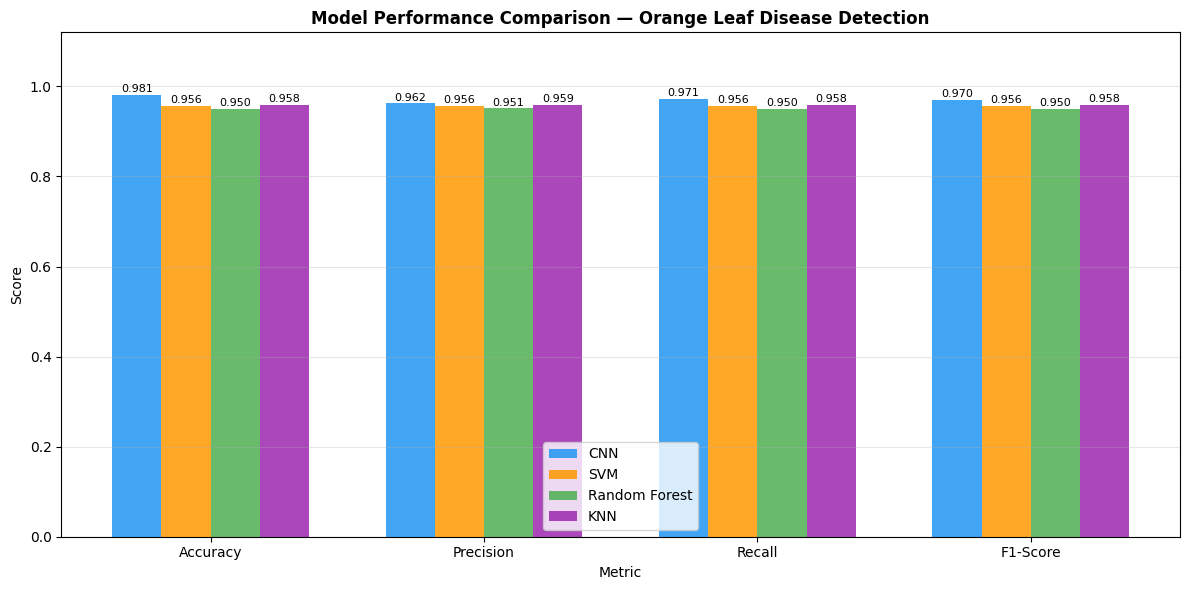

✅ Performance chart saved


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


models_  = ["CNN", "SVM", "Random Forest", "KNN"]
metrics_ = ["Accuracy", "Precision", "Recall", "F1-Score"]
values_  = np.array([
    [cnn_acc,  cnn_prec,  cnn_rec,  cnn_f1],
    [svm_acc,  svm_prec,  svm_rec,  svm_f1],
    [rf_acc,   rf_prec,   rf_rec,   rf_f1],
    [knn_acc,  knn_prec,  knn_rec,  knn_f1],
])

x = np.arange(len(metrics_))
width = 0.18
colors = ["#2196F3", "#FF9800", "#4CAF50", "#9C27B0"]

fig, ax = plt.subplots(figsize=(12, 6))
for i, (model, color) in enumerate(zip(models_, colors)):
    bars = ax.bar(x + i*width, values_[i], width, label=model, color=color, alpha=0.85)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)

ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_title("Model Performance Comparison — Orange Leaf Disease Detection", fontweight="bold")
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics_)
ax.set_ylim(0, 1.12)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/performance_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Performance chart saved")

In [ ]:
import pickle

# CNN
cnn_model.save(f"{SAVE_DIR}/cnn_model.h5")
print(f"✅ CNN saved → {SAVE_DIR}/cnn_model.h5")

# SVM
with open(f"{SAVE_DIR}/svm_model.pkl", "wb") as f:
    pickle.dump(svm_model, f)
print(f"✅ SVM saved → {SAVE_DIR}/svm_model.pkl")

# Random Forest
with open(f"{SAVE_DIR}/rf_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)
print(f"✅ RF  saved → {SAVE_DIR}/rf_model.pkl")

# KNN
with open(f"{SAVE_DIR}/knn_model.pkl", "wb") as f:
    pickle.dump(knn_model, f)
print(f"✅ KNN saved → {SAVE_DIR}/knn_model.pkl")

# Scaler
with open(f"{SAVE_DIR}/scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
print(f"✅ Scaler saved → {SAVE_DIR}/scaler.pkl")

print(f"\n📁 All files in {SAVE_DIR}:")
for f in os.listdir(SAVE_DIR):
    size = os.path.getsize(f"{SAVE_DIR}/{f}") / 1024
    print(f"  {f}  ({size:.1f} KB)")

✅ CNN saved → /content/models/cnn_model.h5
✅ SVM saved → /content/models/svm_model.pkl
✅ RF  saved → /content/models/rf_model.pkl
✅ KNN saved → /content/models/knn_model.pkl
✅ Scaler saved → /content/models/scaler.pkl

📁 All files in /content/models:
  svm_model.pkl  (589.3 KB)
  scaler.pkl  (6.5 KB)
  rf_model.pkl  (3312.7 KB)
  metadata.json  (27.8 KB)
  cnn_phase1_best.h5  (13439.3 KB)
  cnn_best.h5  (27538.0 KB)
  cnn_model.h5  (27537.8 KB)
  knn_model.pkl  (1693.8 KB)
  performance_comparison.png  (53.3 KB)


In [ ]:
from google.colab import files
import shutil

shutil.make_archive("/content/orange_disease_models", "zip", SAVE_DIR)
print("📦 Archive created: orange_disease_models.zip")
size_mb = os.path.getsize("/content/orange_disease_models.zip") / (1024*1024)
print(f"   Size: {size_mb:.1f} MB")
files.download("/content/orange_disease_models.zip")
print("📥 Download started!")

📦 Archive created: orange_disease_models.zip
   Size: 62.4 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📥 Download started!


📦 Loading saved models...


✅ All models loaded

📤 Please upload an orange leaf image (.jpg/.png)...


Saving canker_0260.jpg to canker_0260.jpg

--- Analyzing: canker_0260.jpg ---


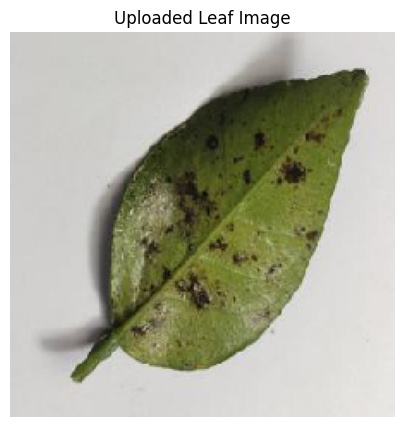


🔍 PREDICTION RESULTS
  CNN            → Canker               (99.7% confidence)
  SVM            → Canker               (99.7% confidence)
  Random Forest  → Canker               (99.0% confidence)
  KNN            → Canker               (100.0% confidence)

🏆 Majority Vote: Canker


In [ ]:


import os, pickle, numpy as np
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing import image as keras_image
from google.colab import files
import matplotlib.pyplot as plt

SAVE_DIR = "/content/models"
IMG_SIZE = (224, 224)

# 🔧 EDIT if your real class names/order differ from training
CLASSES = ["Canker", "Greening", "Black_Spot", "Nutrient_Deficiency"]

print("📦 Loading saved models...")
cnn_model = tf.keras.models.load_model(f"{SAVE_DIR}/cnn_model.h5")

with open(f"{SAVE_DIR}/svm_model.pkl", "rb") as f:
    svm_model = pickle.load(f)
with open(f"{SAVE_DIR}/rf_model.pkl", "rb") as f:
    rf_model = pickle.load(f)
with open(f"{SAVE_DIR}/knn_model.pkl", "rb") as f:
    knn_model = pickle.load(f)
with open(f"{SAVE_DIR}/scaler.pkl", "rb") as f:
    scaler = pickle.load(f)

# Rebuild the feature extractor exactly as in training (GAP output, 1280-dim)
feature_extractor = tf.keras.Model(
    inputs=cnn_model.input,
    outputs=cnn_model.layers[-4].output
)
print("✅ All models loaded\n")


def predict_image(img_path):
    img = keras_image.load_img(img_path, target_size=IMG_SIZE)
    img_array = keras_image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    # CNN
    cnn_probs = cnn_model.predict(img_array, verbose=0)[0]
    cnn_pred, cnn_conf = CLASSES[np.argmax(cnn_probs)], np.max(cnn_probs) * 100

    # Shared features for SVM / RF / KNN
    feat = feature_extractor.predict(img_array, verbose=0)
    feat_scaled = scaler.transform(feat)

    svm_pred = CLASSES[svm_model.predict(feat_scaled)[0]]
    svm_conf = np.max(svm_model.predict_proba(feat_scaled)[0]) * 100

    rf_pred = CLASSES[rf_model.predict(feat_scaled)[0]]
    rf_conf = np.max(rf_model.predict_proba(feat_scaled)[0]) * 100

    knn_pred = CLASSES[knn_model.predict(feat_scaled)[0]]
    knn_conf = np.max(knn_model.predict_proba(feat_scaled)[0]) * 100

    results = {
        "CNN":           (cnn_pred, cnn_conf),
        "SVM":           (svm_pred, svm_conf),
        "Random Forest": (rf_pred, rf_conf),
        "KNN":           (knn_pred, knn_conf),
    }

    plt.figure(figsize=(5,5))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Uploaded Leaf Image")
    plt.show()

    print("\n🔍 PREDICTION RESULTS")
    print("="*45)
    for name, (pred, conf) in results.items():
        print(f"  {name:<14} → {pred:<20} ({conf:.1f}% confidence)")
    print("="*45)

    votes = [v[0] for v in results.values()]
    final = max(set(votes), key=votes.count)
    print(f"\n🏆 Majority Vote: {final}")
    return results


print("📤 Please upload an orange leaf image (.jpg/.png)...")
uploaded = files.upload()
for fname in uploaded.keys():
    print(f"\n--- Analyzing: {fname} ---")
    predict_image(fname)

        Model  Accuracy  Precision  Recall  F1-Score  Training Time (s)  Inference Time (ms)
          CNN    0.9806     0.9621  0.9714    0.9695                NaN              58.4331
          SVM    0.9556     0.9558  0.9556    0.9556            35.4872               0.1204
Random Forest    0.9500     0.9509  0.9500    0.9501            95.2560               0.1859
          KNN    0.9583     0.9588  0.9583    0.9583             0.0013               0.0478


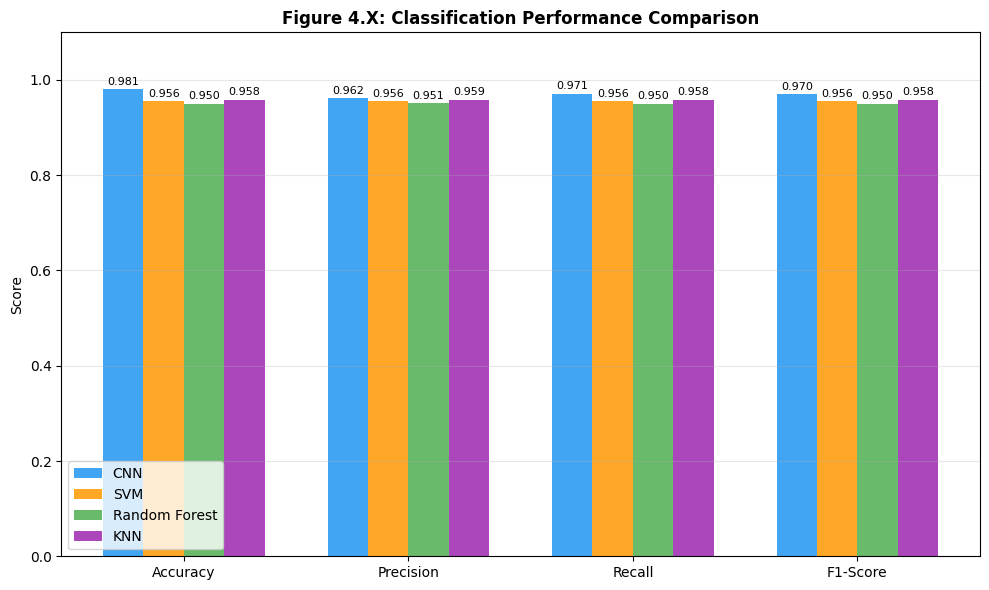

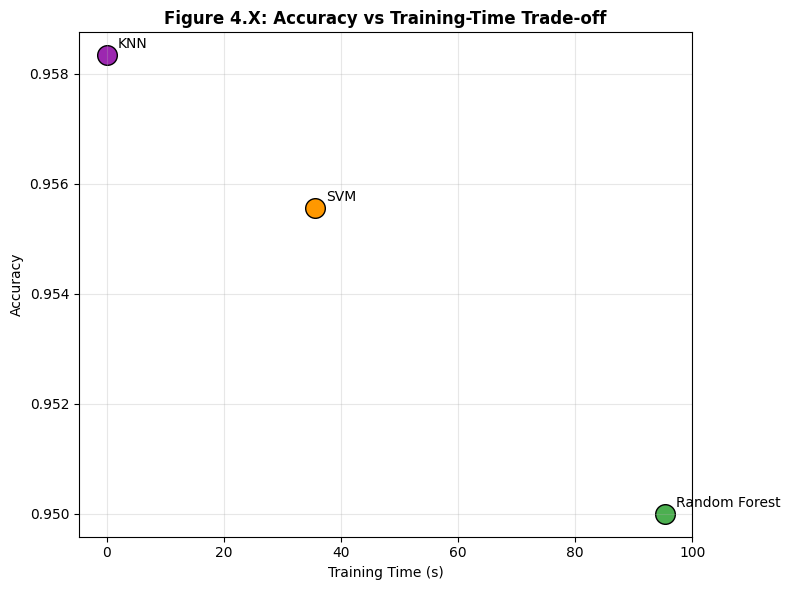

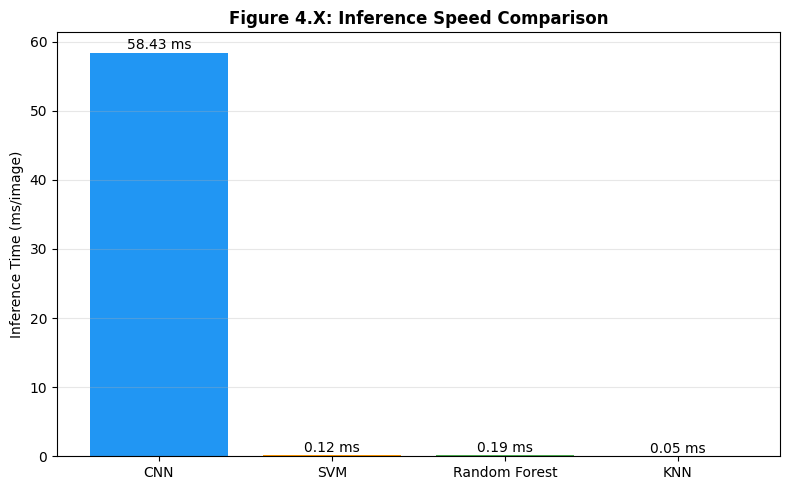

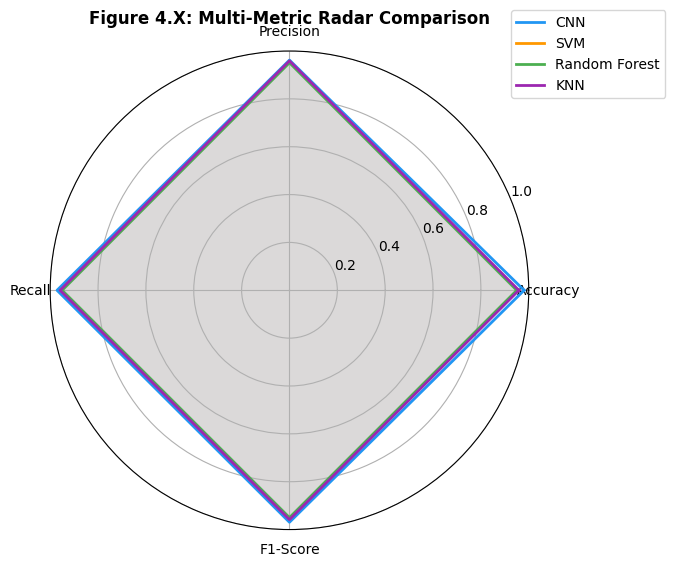

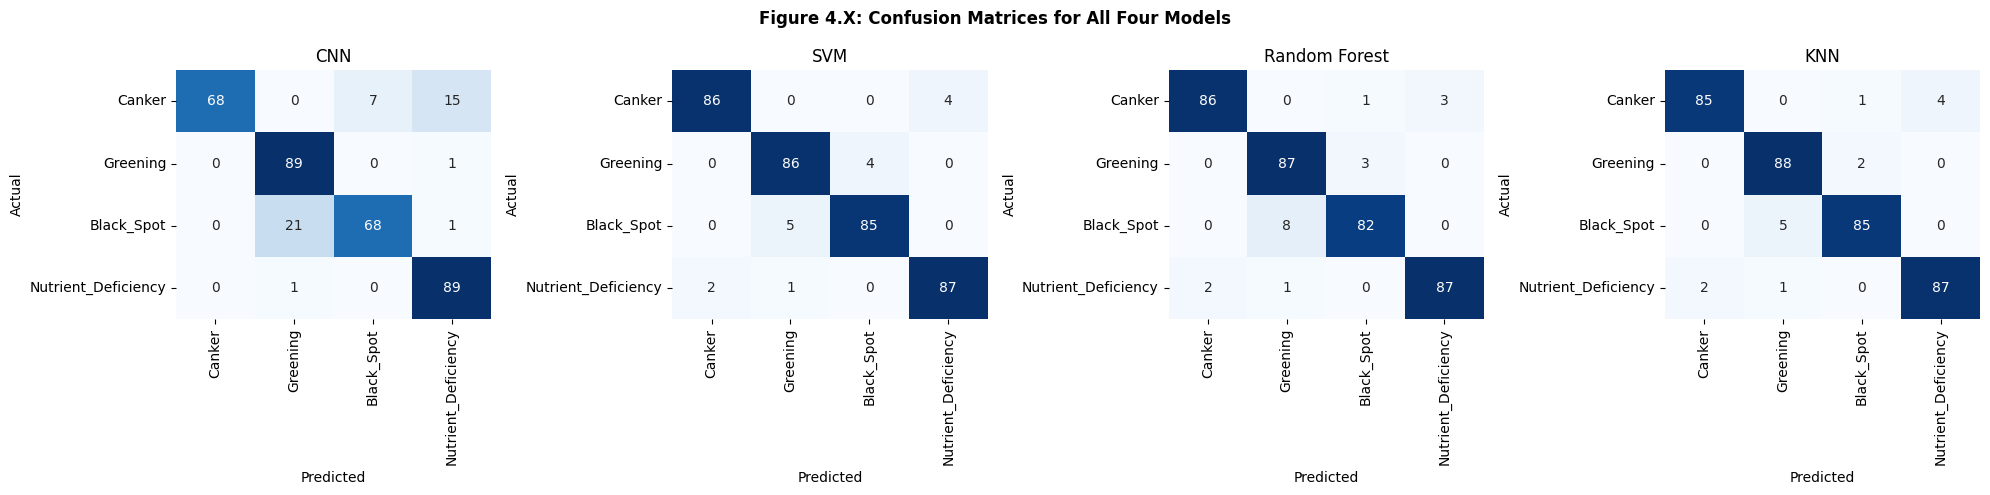


✅ All Chapter 4 charts + summary table saved in /content/models


In [ ]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

SAVE_DIR = "/content/models"
with open(f"{SAVE_DIR}/metadata.json") as f:
    results = json.load(f)

CLASSES = results["classes"]
models_ = ["CNN", "SVM", "Random_Forest", "KNN"]
labels_ = ["CNN", "SVM", "Random Forest", "KNN"]
colors  = ["#2196F3", "#FF9800", "#4CAF50", "#9C27B0"]

# ---- 1. Summary table ----
summary_df = pd.DataFrame({
    "Model": labels_,
    "Accuracy": [results[m]["accuracy"] for m in models_],
    "Precision": [results[m]["precision"] for m in models_],
    "Recall": [results[m]["recall"] for m in models_],
    "F1-Score": [results[m]["f1_score"] for m in models_],
    "Training Time (s)": [results[m]["training_time"] for m in models_],
    "Inference Time (ms)": [results[m]["inference_time_ms"] for m in models_],
})
print(summary_df.round(4).to_string(index=False))
summary_df.round(4).to_csv(f"{SAVE_DIR}/chapter4_summary_table.csv", index=False)

# ---- 2. Grouped bar: classification metrics ----
metrics_ = ["Accuracy", "Precision", "Recall", "F1-Score"]
values_ = summary_df[metrics_].values
x = np.arange(len(metrics_)); width = 0.18

fig, ax = plt.subplots(figsize=(10,6))
for i, (model, color) in enumerate(zip(labels_, colors)):
    bars = ax.bar(x + i*width, values_[i], width, label=model, color=color, alpha=0.85)
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x + width*1.5); ax.set_xticklabels(metrics_)
ax.set_ylim(0,1.1); ax.set_ylabel("Score")
ax.set_title("Figure 4.X: Classification Performance Comparison", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/fig_classification_performance.png", dpi=150); plt.show()

# ---- 3. Accuracy vs Training time trade-off ----
fig, ax = plt.subplots(figsize=(8,6))
for i, model in enumerate(labels_):
    t, a = summary_df["Training Time (s)"][i], summary_df["Accuracy"][i]
    if t is not None:
        ax.scatter(t, a, s=200, color=colors[i], edgecolor="black", label=model)
        ax.annotate(model, (t, a), textcoords="offset points", xytext=(8,5))
ax.set_xlabel("Training Time (s)"); ax.set_ylabel("Accuracy")
ax.set_title("Figure 4.X: Accuracy vs Training-Time Trade-off", fontweight="bold")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/fig_efficiency_tradeoff.png", dpi=150); plt.show()

# ---- 4. Inference time bar ----
fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(labels_, summary_df["Inference Time (ms)"], color=colors)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
             f"{bar.get_height():.2f} ms", ha="center", va="bottom")
ax.set_ylabel("Inference Time (ms/image)")
ax.set_title("Figure 4.X: Inference Speed Comparison", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/fig_inference_time.png", dpi=150); plt.show()

# ---- 5. Radar chart: multi-metric overview ----
N = len(metrics_)
angles = [n/float(N)*2*pi for n in range(N)] + [0]
fig, ax = plt.subplots(figsize=(7,7), subplot_kw=dict(polar=True))
for i, model in enumerate(labels_):
    vals = list(values_[i]) + [values_[i][0]]
    ax.plot(angles, vals, color=colors[i], linewidth=2, label=model)
    ax.fill(angles, vals, color=colors[i], alpha=0.08)
ax.set_xticks(angles[:-1]); ax.set_xticklabels(metrics_); ax.set_ylim(0,1)
ax.set_title("Figure 4.X: Multi-Metric Radar Comparison", fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3,1.1))
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/fig_radar_comparison.png", dpi=150); plt.show()

# ---- 6. Confusion matrices, side by side ----
fig, axes = plt.subplots(1, 4, figsize=(20,5))
for i, (m, label) in enumerate(zip(models_, labels_)):
    cm = np.array(results[m]["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i],
                xticklabels=CLASSES, yticklabels=CLASSES, cbar=False)
    axes[i].set_title(label); axes[i].set_xlabel("Predicted"); axes[i].set_ylabel("Actual")
plt.suptitle("Figure 4.X: Confusion Matrices for All Four Models", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/fig_confusion_matrices.png", dpi=150); plt.show()

print("\n✅ All Chapter 4 charts + summary table saved in", SAVE_DIR)